# Default Credit Card: Exploratory and Statistical Analysis

## Part I — Exploratory Data Analysis

### 1.1 Introduction and Initial Data Inspection

This case study examines the supplied credit card client dataset.
The analysis explores customer characteristics, credit-related
measurements, repayment information, and next-month default status.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

# Read the supplied file without modifying the original data.
data_path = Path("DefaultCreditCard.csv")
df_raw = pd.read_csv(data_path)

# Use a separate copy for subsequent analysis.
df = df_raw.copy()

print("Number of observations:", df.shape[0])
print("Number of variables:", df.shape[1])

display(df.head())

Number of observations: 1000
Number of variables: 25


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,30,50000.0,1,1,2,26,0,0,0,0,...,17907.0,18375.0,11400.0,1500.0,1500.0,1000.0,1000.0,1600.0,0.0,0
1,64,50000.0,2,2,1,46,0,0,0,-2,...,0.0,0.0,0.0,1000.0,0.0,0.0,0.0,0.0,0.0,1
2,72,320000.0,1,2,2,29,2,2,2,2,...,58622.0,62307.0,63526.0,2500.0,2500.0,0.0,4800.0,2400.0,1600.0,1
3,113,280000.0,1,2,1,41,2,2,2,2,...,144401.0,152174.0,149415.0,6500.0,0.0,14254.0,14850.0,0.0,5000.0,0
4,133,420000.0,1,2,1,34,0,0,0,0,...,220951.0,210606.0,188108.0,9744.0,9553.0,7603.0,7830.0,7253.0,11326.0,0


In [2]:
# Inspect storage types, missing values, and distinct values.
data_check = pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Missing values": df.isna().sum(),
    "Unique values": df.nunique(dropna=False)
})

display(data_check)

print("Total missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Duplicate IDs:", int(df["ID"].duplicated().sum()))

# Check that the outcome contains only the expected binary codes.
target = "default.payment.next.month"
assert df[target].isin([0, 1]).all(), "Unexpected default codes found."

default_summary = (
    df[target]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("Default code")
    .to_frame("Number of clients")
)

default_summary["Percentage (%)"] = (
    default_summary["Number of clients"] / len(df) * 100
)

display(default_summary.round(4))

,Data type,Missing values,Unique values
ID,int64,0,1000
LIMIT_BAL,float64,0,57
SEX,int64,0,2
EDUCATION,int64,0,6
MARRIAGE,int64,0,4
AGE,int64,0,45
PAY_0,int64,0,10
PAY_2,int64,0,10
PAY_3,int64,0,9
PAY_4,int64,0,8


Total missing values: 0
Duplicate rows: 0
Duplicate IDs: 0


,Number of clients,Percentage (%)
Default code,,
0,784,78.4
1,216,21.6


### 1.2 Data Quality and Variable Types

The supplied dataset contains 1,000 observations and 25 original variables. Each observation represents one credit card client. There are no missing values detected by pandas, no fully duplicated rows, and no duplicated client IDs.

The next-month default variable contains 216 defaults and 784 non-defaults, giving a sample default rate of 21.6%.

ID is an identifier rather than a numerical measurement. LIMIT_BAL, AGE, the bill amounts, and the payment amounts are quantitative variables. SEX, EDUCATION, MARRIAGE, and the default indicator are categorical variables, although they are stored as integers. The repayment-status variables are coded categories and should not automatically be treated as continuous measurements.

The absence of missing values does not guarantee that every code has a clearly documented meaning. Category codes will be checked before they are interpreted or recoded.

The original data are retained. No observations are removed merely because their values are large or because a bill amount is negative. Such values require investigation rather than automatic deletion.

### 1.3 Numerical Descriptive Statistics

The following table summarises credit limit, age, and the bill and payment amounts recorded in BILL_AMT1 and PAY_AMT1.

The mean and median describe the centre of each distribution. The sample standard deviation and quartiles describe its spread.

In [3]:
# Select quantitative variables for the descriptive summary.
numeric_columns = [
    "LIMIT_BAL",
    "AGE",
    "BILL_AMT1",
    "PAY_AMT1"
]

# describe() calculates the count, mean, sample standard deviation,
# minimum, quartiles, and maximum.
# .T puts variables in rows, making the table easier to read.
descriptive_stats = df[numeric_columns].describe().T

descriptive_stats = descriptive_stats.rename(columns={
    "count": "N",
    "mean": "Mean",
    "std": "SD",
    "min": "Minimum",
    "25%": "Q1",
    "50%": "Median",
    "75%": "Q3",
    "max": "Maximum"
})

display(descriptive_stats.round(4))

,N,Mean,SD,Minimum,Q1,Median,Q3,Maximum
LIMIT_BAL,1000.0,174080.000,132714.6065,10000.0,60000.00,150000.0,250000.00,680000.0
AGE,1000.0,35.412,9.4155,21.0,28.00,34.0,41.00,66.0
BILL_AMT1,1000.0,51341.698,74935.4060,-9095.0,2902.50,20952.5,68287.75,568532.0
PAY_AMT1,1000.0,5942.817,15732.8510,0.0,861.75,2100.0,5253.00,244500.0


#### Interpretation of the Numerical Summary

The mean credit limit is 174,080, compared with a median of 150,000.The higher mean suggests that larger credit limits pull the average upward. The distribution will be examined further using visualisation.

The mean age is 35.412 years and the median is 34 years. 

For BILL_AMT1, the mean is 51,341.698 and the median is 20,952.5. For PAY_AMT1, the mean is 5,942.817 and the median is 2,100. These substantial mean–median differences suggest right-skewed distributions, which will require graphical inspection.

From a business perspective, relying only on average monetary amounts may give an incomplete picture of a typical customer. Reporting medians and quartiles alongside means helps describe both typical values and variation across clients.

### 1.4 Categorical Descriptive Statistics

The following tables report the number and percentage of clients in each category of SEX, EDUCATION, MARRIAGE, and next-month default status.

The original category codes are retained at this stage. These codes represent categories not the numerical quantities, so their means and standard deviations are not used to describe the groups.

Percentages in each table use all 1,000 clients as the denominator. These percentages describe the composition of the sample.

In [4]:
# Summarise categorical variables using counts and percentages.
categorical_columns = [
    "SEX",
    "EDUCATION",
    "MARRIAGE",
    "default.payment.next.month"
]

for column in categorical_columns:
    counts = df[column].value_counts(dropna=False).sort_index()

    summary = counts.rename_axis("Category code").to_frame(
        name="Number of clients"
    )

    summary["Percentage (%)"] = (
        summary["Number of clients"] / len(df) * 100
    )

    print(f"\nVariable: {column}")

    display(
        summary.style.format({
            "Number of clients": "{:.0f}",
            "Percentage (%)": "{:.4f}"
        })
    )


Variable: SEX


,Number of clients,Percentage (%)
Category code,,
1,397,39.7000
2,603,60.3000



Variable: EDUCATION


,Number of clients,Percentage (%)
Category code,,
1,343,34.3000
2,479,47.9000
3,162,16.2000
4,5,0.5000
5,10,1.0000
6,1,0.1000



Variable: MARRIAGE


,Number of clients,Percentage (%)
Category code,,
0,1,0.1000
1,465,46.5000
2,526,52.6000
3,8,0.8000



Variable: default.payment.next.month


,Number of clients,Percentage (%)
Category code,,
0,784,78.4000
1,216,21.6000


#### Interpretation of the Categorical Summary

For SEX, category 1 contains 397 clients (39.7%) and category 2 contains 603 clients (60.3%). These percentages describe the composition of the sample. Although the final second research question focuses on recent repayment status instead, sex is  still retained in the descriptive overview.

For EDUCATION, codes 1, 2, and 3 account for 34.3%, 47.9%, and 16.2% of the sample, respectively. Codes 4, 5, and 6 together account for 1.6%. 

MARRIAGE includes one observation coded 0. The meanings of these codes require reference to the data documentation; they are not automatically treated as missing values or deleted.

There are 216 clients with next-month default status 1 and 784 with status 0. The overall sample default rate is therefore 21.6%. This provides a descriptive baseline for the subsequent group comparisons.

From a business perspective, the category counts help identify unequal group sizes and small categories. 

### 1.5 Exploratory analysis with visualizations

#### 1.5.1 Credit Limit by Next-Month Default Status

The following boxplots compare the distribution of credit limits between clients who do not default and those who default in the next month.

The line inside each box represents the median. The box extends from the first quartile to the third quartile. Whiskers extend to the most extreme observations within 1.5 interquartile ranges of the box. Observations beyond the whiskers are displayed individually and are retained in the analysis.

Mean credit limits are shown as diamond markers. This allows the mean and median to be compared within each group.

,N,Mean,Median,SD
Next-month default status,,,,
No default,784,185216.8367,160000.0000,134916.6676
Default,216,133657.4074,95000.0000,115995.4018


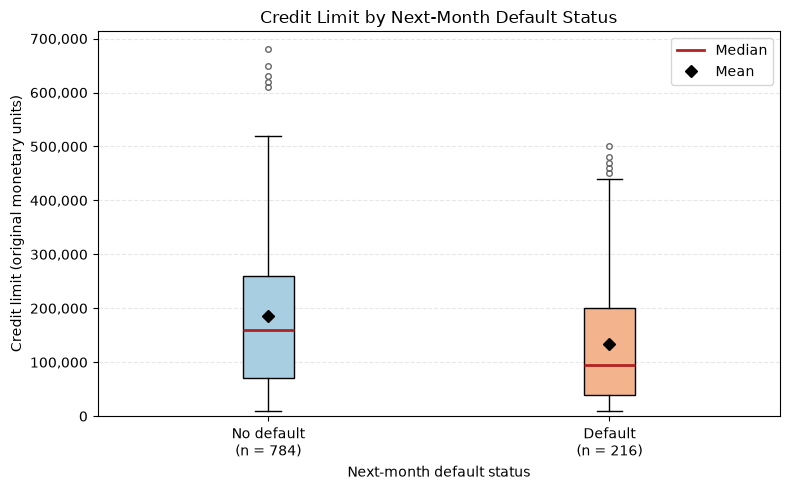

In [5]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import StrMethodFormatter

target = "default.payment.next.month"

# Select credit limits for the two groups.
non_default_limits = df.loc[df[target] == 0, "LIMIT_BAL"]
default_limits = df.loc[df[target] == 1, "LIMIT_BAL"]

# Display group statistics to support the interpretation.
credit_summary = (
    df.groupby(target)["LIMIT_BAL"]
    .agg(["count", "mean", "median", "std"])
    .reindex([0, 1])
)

credit_summary.index = ["No default", "Default"]
credit_summary.index.name = "Next-month default status"
credit_summary.columns = ["N", "Mean", "Median", "SD"]

display(
    credit_summary.style.format({
        "N": "{:.0f}",
        "Mean": "{:.4f}",
        "Median": "{:.4f}",
        "SD": "{:.4f}"
    })
)

# Create boxplots without removing extreme observations.
fig, ax = plt.subplots(figsize=(8, 5))

boxplot = ax.boxplot(
    [non_default_limits, default_limits],
    patch_artist=True,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 6
    },
    medianprops={
        "color": "#B22222",
        "linewidth": 2
    },
    flierprops={
        "marker": "o",
        "markerfacecolor": "none",
        "markeredgecolor": "#666666",
        "markersize": 4
    }
)

for box, color in zip(
    boxplot["boxes"], ["#A8CEE2", "#F2B38D"]
):
    box.set_facecolor(color)

ax.set_xticks([1, 2])
ax.set_xticklabels([
    f"No default\n(n = {len(non_default_limits)})",
    f"Default\n(n = {len(default_limits)})"
])

ax.set_title("Credit Limit by Next-Month Default Status")
ax.set_xlabel("Next-month default status")
ax.set_ylabel("Credit limit (original monetary units)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_ylim(bottom=0)

legend_items = [
    Line2D(
        [0], [0], color="#B22222",
        linewidth=2, label="Median"
    ),
    Line2D(
        [0], [0], marker="D", color="black",
        linestyle="None", markersize=6, label="Mean"
    )
]
ax.legend(handles=legend_items, loc="upper right")

ax.yaxis.grid(True, linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Interpretation and Business Implication

Clients who default in the next month have a lower median credit limit (95,000) than clients who do not default (160,000). The corresponding sample means are 133,657.4074 and 185,216.8367.

In both groups, the mean exceeds the median, suggesting that higher credit limits pull the average upward. The middle 50% of credit limits ranges from 40,000 to 200,000 in the default group and from 70,000 to 260,000 in the non-default group.

The overlapping degree of distribution areas is high, so the credit limit alone cannot clearly distinguish between defaulting customers and non-defaulting customers. The outliers in the box plot are still retained; this rule marking does not indicate that there is an error in the data. 

From a business perspective, this difference prompts us to further study the relationship between the existing credit allocation and the default results.


#### 1.5.2 Next-Month Default Rate by Recent Repayment Status

PAY_0 records repayment status in September 2005, the most recent month of repayment history in this dataset. According to the UCI documentation, positive repayment-status codes indicate months of payment delay.

Clients are divided into two groups: PAY_0 > 0 and PAY_0 <= 0. The latter is a comparison group with no positive delay code in that month, not a group proven never to have been overdue. Since UCI dataset documentation does not fully explain codes -2 and 0, so no more detailed interpretation is assigned to them here.

The chart compares within-group next-month default rates. The overall sample default rate is shown as a reference.

Source: [UCI dataset documentation](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients).

,Number of clients,Number of defaults,Number of non-defaults,Default rate (%)
Recent repayment status,,,,
PAY_0 <= 0,764,106,658,13.8743
PAY_0 > 0,236,110,126,46.6102


Delay-coded minus comparison group: 32.7358 percentage points


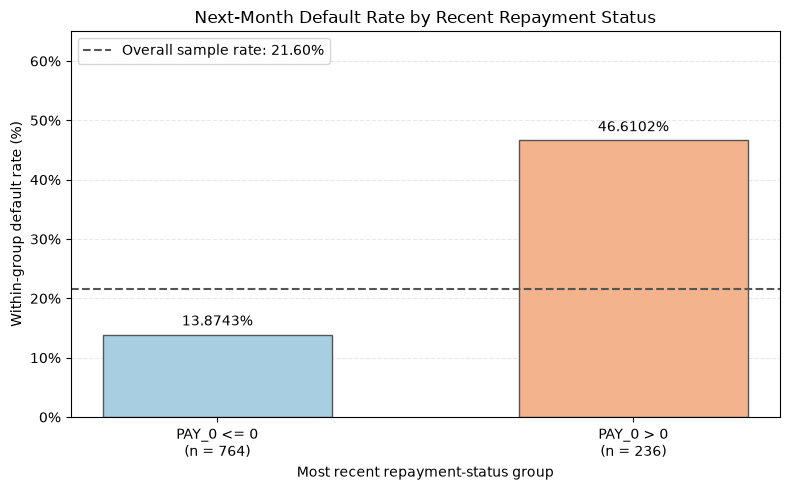

In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

target = "default.payment.next.month"

# Check that the variables needed for grouping are complete.
assert df["PAY_0"].notna().all()
assert df[target].isin([0, 1]).all()

# Create a separate analysis table without changing the raw data.
delay_data = df[["PAY_0", target]].copy()
delay_data["Delay flag"] = (delay_data["PAY_0"] > 0).astype(int)

# 0 = PAY_0 <= 0; 1 = PAY_0 > 0.
delay_summary = (
    delay_data.groupby("Delay flag")[target]
    .agg(["count", "sum"])
    .reindex([0, 1])
)

delay_summary.columns = ["Number of clients", "Number of defaults"]
delay_summary["Number of non-defaults"] = (
    delay_summary["Number of clients"]
    - delay_summary["Number of defaults"]
)
delay_summary["Default rate (%)"] = (
    delay_summary["Number of defaults"]
    / delay_summary["Number of clients"]
    * 100
)

delay_summary.index = ["PAY_0 <= 0", "PAY_0 > 0"]
delay_summary.index.name = "Recent repayment status"

display(
    delay_summary.style.format({
        "Number of clients": "{:.0f}",
        "Number of defaults": "{:.0f}",
        "Number of non-defaults": "{:.0f}",
        "Default rate (%)": "{:.4f}"
    })
)

rates = delay_summary["Default rate (%)"]
overall_rate = df[target].mean() * 100

difference_pp = rates.loc["PAY_0 > 0"] - rates.loc["PAY_0 <= 0"]
print(
    f"Delay-coded minus comparison group: "
    f"{difference_pp:.4f} percentage points"
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    [0, 1],
    rates.to_numpy(),
    width=0.55,
    color=["#A8CEE2", "#F2B38D"],
    edgecolor="#555555"
)

ax.set_xticks([0, 1])
ax.set_xticklabels([
    f"PAY_0 <= 0\n(n = {delay_summary.iloc[0]['Number of clients']:.0f})",
    f"PAY_0 > 0\n(n = {delay_summary.iloc[1]['Number of clients']:.0f})"
])

for bar, rate in zip(bars, rates):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        rate + 1,
        f"{rate:.4f}%",
        ha="center",
        va="bottom"
    )

ax.axhline(
    overall_rate,
    color="#555555",
    linestyle="--",
    label=f"Overall sample rate: {overall_rate:.2f}%"
)

ax.set_title("Next-Month Default Rate by Recent Repayment Status")
ax.set_xlabel("Most recent repayment-status group")
ax.set_ylabel("Within-group default rate (%)")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_ylim(0, 65)
ax.legend(loc="upper left")

ax.yaxis.grid(True, linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Interpretation and Business Implication

Among 236 clients with PAY_0 > 0, 110 default in the next month, giving a sample default rate of 46.6102%.Among 764 clients with PAY_0 <= 0, 106 default, giving a rate of 13.8743%.

The delay-coded group's sample default rate is higher by 32.7358 percentage points. Its rate also exceeds the overall sample default rate of 21.6%.

This pattern suggests that recent repayment delay may be useful as a warning signal for further risk assessment or customer support. 


#### 1.5.3 Age Distribution of Defaulting Clients

This histogram describes the ages of clients whose next-month default indicator equals 1. Five-year age intervals are used, and vertical lines mark the sample mean and median.

The chart helps assess the centre, spread, and shape of the age distribution before estimating the population mean age of defaulting clients in Part II.

The bar heights represent numbers of defaulting clients.

,N,Mean,SD,Minimum,Q1,Median,Q3,Maximum
Defaulting clients,216,35.5185,9.8934,22.0000,27.7500,34.0000,41.0000,65.0000


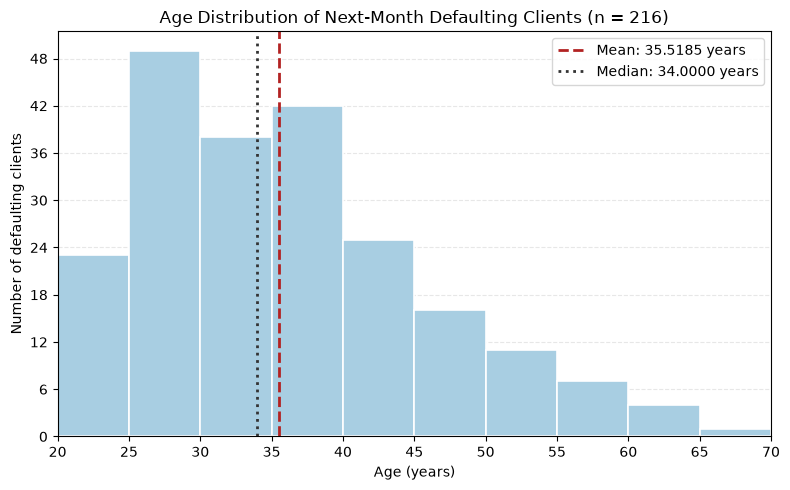

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

target = "default.payment.next.month"

# Select ages only for clients who default in the next month.
default_ages = df.loc[df[target] == 1, "AGE"]

assert default_ages.notna().all(), "Missing ages found."

# Summarise the selected clients.
age_summary = pd.DataFrame({
    "N": [default_ages.count()],
    "Mean": [default_ages.mean()],
    "SD": [default_ages.std(ddof=1)],
    "Minimum": [default_ages.min()],
    "Q1": [default_ages.quantile(0.25)],
    "Median": [default_ages.median()],
    "Q3": [default_ages.quantile(0.75)],
    "Maximum": [default_ages.max()]
}, index=["Defaulting clients"])

display(
    age_summary.style.format({
        "N": "{:.0f}",
        "Mean": "{:.4f}",
        "SD": "{:.4f}",
        "Minimum": "{:.4f}",
        "Q1": "{:.4f}",
        "Median": "{:.4f}",
        "Q3": "{:.4f}",
        "Maximum": "{:.4f}"
    })
)

# Five-year intervals covering all observed ages.
# Bins are 20–24, 25–29, ..., 65–69.
age_bins = np.arange(20, 71, 5)

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    default_ages,
    bins=age_bins,
    color="#A8CEE2",
    edgecolor="white",
    linewidth=1.2
)

ax.axvline(
    default_ages.mean(),
    color="#B22222",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {default_ages.mean():.4f} years"
)

ax.axvline(
    default_ages.median(),
    color="#333333",
    linestyle=":",
    linewidth=2,
    label=f"Median: {default_ages.median():.4f} years"
)

ax.set_title(
    f"Age Distribution of Next-Month Defaulting Clients "
    f"(n = {len(default_ages)})"
)
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of defaulting clients")
ax.set_xticks(age_bins)
ax.set_xlim(20, 70)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend(loc="upper right")

ax.yaxis.grid(True, linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Interpretation and Business Implication

The 216 defaulting clients have a mean age of 35.5185 years and a median age of 34 years. Their ages range from 22 to 65 years, with a sample standard deviation of 9.8934 years.

The first and third quartiles are 27.75 and 41 years, respectively. These values describe the middle portion
of the age distribution. The non-integer first quartile results from interpolation when calculating the sample
quantile.

The mean is higher than the median, suggesting some asymmetry towards older ages. The mean should therefore be considered alongside the median, spread, and histogram.

From a business perspective, the distribution describes the age profile of clients who default and can inform further investigation of their circumstances and support needs. 

In Part II, a 95% t confidence interval will quantify the uncertainty in estimating the population mean age of defaulting clients, subject to the sampling and independence assumptions.

## Part II — Research Questions and Statistical Analysis

### 2.1 Three Research Questions Proposed By The Author：

The following questions record my initial ideas before receiving AI-generated research questions. 

**Question 1:** Does credit card default affect a customer's ability to borrow? Do customers who default and those who do not default have the same borrowing amount?

My initial motivation was to understand the possible borrowing consequences of default and the importance of timely repayment. I initially expected to use default information and borrowing amount.

**Question 2:** Is the default rate related to sex?

My initial motivation was to investigate whether differences between groups could inform credit-limit decisions and reduce default. I expected to use sex and default information.

**Question 3:** What is the average age of customers who default?

My initial motivation was to understand the age profile of defaulting customers and whether age could inform credit-card issuance decisions. I expected to use age and default information.

### 2.2 Research Questions Proposed by AI

**AI tool:** ChatGPT、Github Copilot

**Prompt:** Using the supplied DefaultCreditCard.csv dataset, propose three
business-relevant research questions that can be answered using
introductory statistical methods from my course, such as confidence
intervals, hypothesis tests, correlation, or simple linear regression.
Identify the variables and a suitable method for each question.

**AI response:**

ChatGPT

#### Question 1: What is the next-month default proportion in the population represented by this dataset?

Variable: default.payment.next.month (1 = default; 0 = no default).

Method: Calculate the sample default proportion and construct a 95% confidence interval for the population proportion. A normal-approximation interval can be used if the observed numbers of defaults and non-defaults are sufficiently large.

Business relevance: Estimating the default proportion provides a baseline measure of credit risk that can inform portfolio monitoring.

Limitation: Generalisation depends on how the supplied sample was selected and which population it represents. The estimate should not automatically be applied to all credit card customers or current market conditions.

#### Question 2: Does the mean credit limit differ between customers who default in the next month and those who do not?

Variables: LIMIT_BAL and default.payment.next.month.

Method: Use a two-sided Welch independent-samples t-test to compare the population mean credit limits of the two groups. Examine group sizes, distributions, and extreme values before interpreting the test.
$$
H_0:\mu_{\text{default}}=\mu_{\text{non-default}}
$$

$$
H_1:\mu_{\text{default}}\ne\mu_{\text{non-default}}
$$
Business relevance: This comparison can show whether existing credit limits differ between the two outcome groups and motivate further investigation of credit allocation and risk.

Limitation: LIMIT_BAL measures a credit limit, not a loan amount. A difference would indicate association; it would not establish that default caused a reduction in credit limits or that changing credit limits would change default risk. 

#### Question 3: Is there a linear association between customer age and credit limit?

Variables: AGE and LIMIT_BAL.

Method: Create a scatter plot and calculate Pearson’s correlation coefficient. A simple linear regression with credit limit as the response and age as the explanatory variable may also be used. Check whether a linear summary is reasonable and whether extreme observations strongly influence the results.

Business relevance: The analysis can describe how existing credit limits vary with age and help the bank understand the composition of its credit portfolio.

Limitation: An association does not establish that age causes differences in credit limits. Other relevant characteristics, such as income, are not included in this analysis. The findings alone would not justify age-based lending restrictions.


Github Copilot

#### Question 1: What is the default rate for this group of customers next month?

Variables：default.payment.next.month (1 = default, 0 = not default)

Method：Calculate the default rate and its confidence interval

Business relevance: Provide an estimate of the risk level of the credit portfolio.

#### Question 2: Do customers with overdue records have a higher probability of defaulting next month?

Variables：PAY_0 (current repayment status, can be grouped by whether overdue) and default.payment.next.month

Method：Compare the default rates of the two groups; conduct a two-proportion hypothesis test and report the confidence interval of the difference in proportions.

Business relevance: Determine whether the current overdue status is worthy of being regarded as a risk warning signal. We can define PAY_0 > 0 as the overdue group; this result represents an association, but not causation.

#### Question 3: Do customers with higher credit limits also have higher bill amounts?

Variables：LIMIT_BAL (Credit Limit) and BILL_AMT1 (Amount of the Latest Bill)

Method：Draw a scatter plot, calculate the Pearson correlation coefficient, and conduct simple linear regression.

Business relevance: Help to understand the relationship between the credit limit and the scale of the customer's bill, and provide a reference for credit limit management.


### 2.3 Comparison and Selection of the Final Research Questions

I compared my initial questions with the AI-generated suggestions. I selected the following three questions because they preserve my main interests and thinkings. Those questions also can answer using the available variables and introductory statistical methods.

#### Final Question 1: Does the mean credit limit differ between customers who default in the next month and those who do not?

**Source:** A combination of my initial question and AI assistance.

My original question concerned borrowing amounts and the possible consequences of default. After reviewing the variables, I recognised that LIMIT_BAL measures a credit limit rather than a loan amount. The data also do not show changes in borrowing capacity after default. I therefore revised the question to compare credit limits between the two default-status groups. This revised question also matches the second AI-proposed question.

**Variables:** LIMIT_BAL and default.payment.next.month.

**Planned method:** A two-sided Welch independent-samples t-test, with a 95% confidence interval for the difference in population means. Group sizes, distributions, and extreme values will be examined.

**Business relevance:** The comparison can identify whether existing credit limits differ between the two outcome groups and motivate further investigation of credit allocation and risk. This will enable us to better assist banks in reducing the probability of credit card default.


#### Final Question 2: Does the next-month default proportion differ between clients with and without a positive repayment-delay code in the most recent month?

**Source:** From a GitHub Copilot suggestion, selected after comparison with my original question.

My initial question compared default proportions by sex. After reviewing additional questions suggested by GitHub Copilot, I selected repayment status instead because it is more directly related to repayment behaviour and potential risk monitoring.

**Variables:** PAY_0 and default.payment.next.month.

**Planned method:** A two-sided two-proportion z-test, after checking the relevant group counts, together with a 95% confidence interval for the difference in population proportions. The difference is defined as the delay-coded group minus the comparison group.

**Business relevance:** The analysis evaluates whether recent repayment delay is associated with next-month default and may therefore warrant further investigation as a risk warning signal. Encouraging banks to enhance their risk awareness


#### Final Question 3: What is the estimated population mean age of customers who default in the next month?

**Source:** Mainly my own initial question, refined with AI assistance.

I retained my original question about the average age of defaulting customers. AI suggested adding a confidence interval to show the uncertainty associated with estimating a population mean from a sample.

**Variables:** AGE, restricted to customers for whom default.payment.next.month equals 1.

**Planned method:** Calculate the sample mean and construct a 95% one-sample t confidence interval for the population mean age of defaulting customers.

**Business relevance:** This analysis describes the age profile of defaulting customers. This enables us to have a basic understanding of the approximate age distribution of defaulters, and provides a reference for improving the situation of credit card defaults.


#### Comparison with the Other AI Suggestions

I retained the credit-limit comparison and the mean-age question because they preserve two of my original research interests and thinking.

I replaced the sex comparison with Copilot's repayment-status question because recent repayment behaviour has a more direct connection to potential credit-risk monitoring.

In the Part I, the overall default rate can still be used as a descriptive statistical basis, but it was not selected as the final research question. This is because although the proposed relationships between age and credit limit, and between credit limit and bill amount are feasible, they have relatively weak correlation with the main focus of my research on default outcomes. Therefore, these two issues were not chosen in the end. The main consideration for my final research question was its relevance and feasibility.


### 2.4 Research Question 1: Mean Credit Limit by Default Status

Does the population mean credit limit differ between clients who default in the next month and those who do not?

#### Hypotheses

Let $\mu_D$ denote the population mean credit limit of defaulting clients, and $\mu_N$ that of non-defaulting clients.

$$
H_0: \mu_D - \mu_N = 0
$$

$$
H_1: \mu_D - \mu_N \ne 0
$$

A two-sided test is used with significance level $\alpha = 0.05$. All differences are defined as default minus non-default.

#### Choice of Method and Assumptions

Welch's independent-samples t-test is used because credit limit is quantitative and the two groups contain different clients. The population variances are unknown and are not assumed equal.

The group sizes are 216 and 784. Although the boxplots suggest right-skewness and some extreme observations, the large group sizes support an approximate normal sampling distribution of each mean. Extreme observations are retained because a boxplot flag alone does not establish that a value is erroneous.

The analysis assumes independent observations and a sample sufficiently representative of the populations being compared. Unique client IDs do not prove independence, and the sampling procedure cannot be established from the CSV alone. Population conclusions are therefore conditional on these assumptions.

#### Test Statistic

$$
t =
\frac{(\bar{x}_D-\bar{x}_N)-0}
{\sqrt{s_D^2/n_D+s_N^2/n_N}}
$$

The Welch-Satterthwaite approximate degrees of freedom are:

$$
\nu =
\frac{(s_D^2/n_D+s_N^2/n_N)^2}
{\frac{(s_D^2/n_D)^2}{n_D-1}
+\frac{(s_N^2/n_N)^2}{n_N-1}}
$$

Here, $\bar{x}$ is a sample mean, $s$ is a sample standard deviation, and $n$ is a group sample size.

A 95% confidence interval for $\mu_D-\mu_N$ is:

$$
(\bar{x}_D-\bar{x}_N)
\pm t_{0.975,\nu}\sqrt{s_D^2/n_D+s_N^2/n_N}
$$

In [8]:
import numpy as np
import pandas as pd
from scipy import stats

target = "default.payment.next.month"

# Select credit limits from the original, unrounded data.
limits_d = df.loc[df[target] == 1, "LIMIT_BAL"]
limits_n = df.loc[df[target] == 0, "LIMIT_BAL"]

assert limits_d.notna().all()
assert limits_n.notna().all()

n_d = len(limits_d)
n_n = len(limits_n)

mean_d = limits_d.mean()
mean_n = limits_n.mean()

sd_d = limits_d.std(ddof=1)
sd_n = limits_n.std(ddof=1)

# Show the group statistics used in the test.
group_table = pd.DataFrame({
    "Group": ["Default", "No default"],
    "N": [n_d, n_n],
    "Mean credit limit": [mean_d, mean_n],
    "SD": [sd_d, sd_n]
}).set_index("Group")

display(
    group_table.style.format({
        "N": "{:.0f}",
        "Mean credit limit": "{:.4f}",
        "SD": "{:.4f}"
    })
)

# Difference: default minus non-default.
mean_difference = mean_d - mean_n

variance_component_d = sd_d**2 / n_d
variance_component_n = sd_n**2 / n_n

standard_error = np.sqrt(
    variance_component_d + variance_component_n
)

welch_df = (
    (variance_component_d + variance_component_n)**2
    / (
        variance_component_d**2 / (n_d - 1)
        + variance_component_n**2 / (n_n - 1)
    )
)

t_statistic = mean_difference / standard_error
p_value = 2 * stats.t.sf(abs(t_statistic), df=welch_df)

# 95% confidence interval for the difference in means.
critical_t = stats.t.ppf(0.975, df=welch_df)
margin = critical_t * standard_error

ci_lower = mean_difference - margin
ci_upper = mean_difference + margin

# Cross-check the manual calculation against SciPy's Welch test.
scipy_result = stats.ttest_ind(
    limits_d,
    limits_n,
    equal_var=False
)

assert np.isclose(t_statistic, scipy_result.statistic)
assert np.isclose(
    p_value, scipy_result.pvalue,
    rtol=1e-10, atol=0
)

results = pd.DataFrame({
    "Statistic": [
        "Mean difference (Default - No default), NT$",
        "Standard error, NT$",
        "Welch degrees of freedom",
        "t statistic",
        "95% CI lower bound, NT$",
        "95% CI upper bound, NT$"
    ],
    "Value": [
        mean_difference,
        standard_error,
        welch_df,
        t_statistic,
        ci_lower,
        ci_upper
    ]
}).set_index("Statistic")

display(results.style.format({"Value": "{:.4f}"}))

# Scientific notation avoids incorrectly displaying a tiny p-value as zero.
print(f"Two-sided p-value: {p_value:.6e}")
print("Manual calculation agrees with SciPy's Welch test.")

if p_value < 0.05:
    print("Decision at alpha = 0.05: Reject H0.")
else:
    print("Decision at alpha = 0.05: Do not reject H0.")

,N,Mean credit limit,SD
Group,,,
Default,216,133657.4074,115995.4018
No default,784,185216.8367,134916.6676


,Value
Statistic,
"Mean difference (Default - No default), NT$",-51559.4293
"Standard error, NT$",9247.0991
Welch degrees of freedom,390.2531
t statistic,-5.5757
"95% CI lower bound, NT$",-69739.7935
"95% CI upper bound, NT$",-33379.0651


Two-sided p-value: 4.609162e-08
Manual calculation agrees with SciPy's Welch test.
Decision at alpha = 0.05: Reject H0.


#### Results and Statistical Interpretation

The sample mean credit limit is NT$133,657.4074 for defaulting clients and NT$185,216.8367 for non-defaulting clients. The estimated mean difference, defined as default minus non-default, is -NT$51,559.4293.

Welch's test gives t = -5.5757 with approximately 390.2531 degrees of freedom and a two-sided p-value of approximately 4.609162 × 10^-8. Since the p-value is below 0.05, the null hypothesis of equal population means is rejected.

The 95% confidence interval for the population mean difference is [-69,739.7935, -33,379.0651] NT$. The entire interval is negative, consistent with a lower mean credit limit in the defaulting population, subject to the stated assumptions.

Expressed in the opposite direction, the interval corresponds to a mean credit limit for defaulting clients that is between NT$33,379.0651 and NT$69,739.7935 lower than that for non-defaulting clients.

#### Business Interpretation and Limitations

The results suggest some evidence of a relationship between existing credit lines and default status in the next month. The differences in estimates can facilitate further research on the relationship between the allocation of credit lines and the risk profile of customers. Promote banks to improve credit card defaults. However, because this is a comparison of different customer groups, rather than a before-after comparison of the same customer group. So it does not show that default will lead to lower credit limits, nor does it show that increasing credit limits will reduce default risk.


### 2.5 Research Question 2: Default Proportions by Recent Repayment Status

Does the population next-month default proportion differ between clients with PAY_0 > 0 and clients with PAY_0 <= 0?

#### Group Definitions and Hypotheses

Let $p_1$ denote the population default proportion for clients with PAY_0 > 0, and $p_0$ that for clients with PAY_0 <= 0.

The comparison concerns the most recent recorded repayment status. PAY_0 <= 0 does not mean that a client has never been overdue.

$$
H_0: p_1-p_0=0
$$

$$
H_1: p_1-p_0\ne 0
$$

A two-sided two-proportion z-test is conducted at $\alpha=0.05$. Differences are defined as the delay-coded group minus the comparison group.

#### Choice of Method and Assumptions

The outcome is binary and the two groups contain different clients. A two-proportion z-test is appropriate when observations are independent and group counts support the normal approximation.

Under the null hypothesis, expected default and non-default counts are calculated using the pooled sample proportion. All four expected counts must be sufficiently large; a threshold of 10 is used here.

The confidence interval uses the separate group proportions. Observed default and non-default counts in both groups are also checked against the threshold of 10.

#### Test Statistic

Let $x_1$ and $x_0$ be the numbers of defaults, and $n_1$ and $n_0$ the group sample sizes.

$$
\hat{p}_1=\frac{x_1}{n_1},
\qquad
\hat{p}_0=\frac{x_0}{n_0}
$$

Under the null hypothesis, the pooled estimate is:

$$
\hat{p}=\frac{x_1+x_0}{n_1+n_0}
$$

The test statistic is:

$$
z=\frac{\hat{p}_1-\hat{p}_0}
{\sqrt{\hat{p}(1-\hat{p})(1/n_1+1/n_0)}}
$$

#### Confidence Interval

An approximate 95% Wald confidence interval for $p_1-p_0$ is:

$$
(\hat{p}_1-\hat{p}_0)
\pm z_{0.975}
\sqrt{
\frac{\hat{p}_1(1-\hat{p}_1)}{n_1}
+
\frac{\hat{p}_0(1-\hat{p}_0)}{n_0}
}
$$

The test uses a pooled standard error under the assumption of equal population proportions. The confidence interval uses an unpooled standard error because it estimates the difference without imposing equality.

In [9]:
import numpy as np
import pandas as pd
from scipy import stats

target = "default.payment.next.month"

assert df["PAY_0"].notna().all()
assert df[target].isin([0, 1]).all()

# Group 1: positive delay code.
# Group 0: non-positive repayment-status code.
outcome_1 = df.loc[df["PAY_0"] > 0, target]
outcome_0 = df.loc[df["PAY_0"] <= 0, target]

n_1 = len(outcome_1)
n_0 = len(outcome_0)

x_1 = int(outcome_1.sum())
x_0 = int(outcome_0.sum())

p_1 = x_1 / n_1
p_0 = x_0 / n_0
difference = p_1 - p_0

group_table_q2 = pd.DataFrame({
    "Group": ["PAY_0 > 0", "PAY_0 <= 0"],
    "N": [n_1, n_0],
    "Defaults": [x_1, x_0],
    "Non-defaults": [n_1 - x_1, n_0 - x_0],
    "Default rate (%)": [p_1 * 100, p_0 * 100]
}).set_index("Group")

display(
    group_table_q2.style.format({
        "N": "{:.0f}",
        "Defaults": "{:.0f}",
        "Non-defaults": "{:.0f}",
        "Default rate (%)": "{:.4f}"
    })
)

# Pooled proportion under H0.
pooled_p = (x_1 + x_0) / (n_1 + n_0)

expected_table = pd.DataFrame({
    "Group": ["PAY_0 > 0", "PAY_0 <= 0"],
    "Expected defaults under H0": [
        n_1 * pooled_p,
        n_0 * pooled_p
    ],
    "Expected non-defaults under H0": [
        n_1 * (1 - pooled_p),
        n_0 * (1 - pooled_p)
    ]
}).set_index("Group")

display(expected_table.style.format("{:.4f}"))

assert (expected_table.to_numpy() >= 10).all()
assert min(x_1, n_1 - x_1, x_0, n_0 - x_0) >= 10

print("Normal-approximation count checks passed.")

# Pooled standard error for the hypothesis test.
se_null = np.sqrt(
    pooled_p * (1 - pooled_p) * (1 / n_1 + 1 / n_0)
)

z_statistic = difference / se_null
p_value_q2 = 2 * stats.norm.sf(abs(z_statistic))

# Unpooled standard error for the confidence interval.
se_ci = np.sqrt(
    p_1 * (1 - p_1) / n_1
    + p_0 * (1 - p_0) / n_0
)

critical_z = stats.norm.ppf(0.975)
ci_lower_q2 = difference - critical_z * se_ci
ci_upper_q2 = difference + critical_z * se_ci

# Cross-check: the uncorrected 2x2 Pearson chi-square
# statistic equals the square of the two-proportion z statistic.
observed = np.array([
    [x_1, n_1 - x_1],
    [x_0, n_0 - x_0]
])

chi2_result = stats.chi2_contingency(
    observed,
    correction=False
)

assert np.isclose(z_statistic**2, chi2_result[0])
assert np.isclose(
    p_value_q2, chi2_result[1],
    rtol=1e-10, atol=0
)

results_q2 = pd.DataFrame({
    "Statistic": [
        "Pooled proportion under H0",
        "Pooled SE for test (proportion units)",
        "z statistic",
        "Unpooled SE for CI (proportion units)",
        "Difference (percentage points)",
        "95% CI lower bound (percentage points)",
        "95% CI upper bound (percentage points)"
    ],
    "Value": [
        pooled_p,
        se_null,
        z_statistic,
        se_ci,
        difference * 100,
        ci_lower_q2 * 100,
        ci_upper_q2 * 100
    ]
}).set_index("Statistic")

display(results_q2.style.format({"Value": "{:.4f}"}))

print(f"Two-sided p-value: {p_value_q2:.6e}")
print("Cross-check against the uncorrected chi-square test passed.")

if p_value_q2 < 0.05:
    print("Decision at alpha = 0.05: Reject H0.")
else:
    print("Decision at alpha = 0.05: Do not reject H0.")

,N,Defaults,Non-defaults,Default rate (%)
Group,,,,
PAY_0 > 0,236,110,126,46.6102
PAY_0 <= 0,764,106,658,13.8743


,Expected defaults under H0,Expected non-defaults under H0
Group,,
PAY_0 > 0,50.9760,185.0240
PAY_0 <= 0,165.0240,598.9760


Normal-approximation count checks passed.


,Value
Statistic,
Pooled proportion under H0,0.2160
Pooled SE for test (proportion units),0.0306
z statistic,10.6817
Unpooled SE for CI (proportion units),0.0348
Difference (percentage points),32.7358
95% CI lower bound (percentage points),25.9157
95% CI upper bound (percentage points),39.5560


Two-sided p-value: 1.239580e-26
Cross-check against the uncorrected chi-square test passed.
Decision at alpha = 0.05: Reject H0.


#### Results and Statistical Interpretation

The delay-coded group has 110 defaults among 236 clients, giving a sample default rate of 46.6102%. The comparison group has 106 defaults among 764 clients, giving a rate of 13.8743%.

All four expected cell counts under the null hypothesis exceed 10. The observed default and non-default counts
in both groups also exceed 10, supporting the count conditions for the normal approximations.

The two-proportion test gives z = 10.6817 and a two-sided p-value of approximately 1.239580 × 10^-26. At the 0.05 significance level, the null hypothesis of equal population default proportions is rejected.

The estimated difference is 32.7358 percentage points. The approximate 95% confidence interval for the population difference is [25.9157, 39.5560] percentage points. The entire interval is positive, supporting a higher population default proportion in the delay-coded group, subject to the stated sampling assumptions.

#### Business Interpretation and Limitations

In this sample, the most recent repayment delay is significantly associated with a much higher default rate in the following month. This indicates that the repayment status of credit cards may be worthy of attention, serving as a warning signal for further assessment and timely customer support. It enables banks to promptly control the risk of default and minimize losses.


### 2.6 Research Question 3: Mean Age of Defaulting Clients

What is the estimated population mean age of clients who default in the next month?

#### Parameter and Method

Let $\mu_D^{age}$ denote the population mean age of defaulting clients. The analysis uses AGE for observations where default.payment.next.month equals 1.

The sample mean is used as a point estimate, and a 95% one-sample t confidence interval quantifies estimation
uncertainty. A t interval is used because the population standard deviation is unknown and is estimated using the sample standard deviation.

This is an estimation question. No benchmark age has been specified, so no hypothesis test or p-value is required.

#### Assumptions

The analysis assumes independent observations and a sample of defaulting clients that adequately represents the relevant population of defaulting clients.

The histogram shows some right-skewness. With 216 observations, the central limit theorem supports an approximately normal sampling distribution of the mean, making the t interval a reasonable large-sample approximation.

The sampling procedure cannot be established from the CSV, so generalisation beyond the sample remains conditional on representativeness.

#### Confidence Interval Formula

$$
\bar{x}\pm t_{0.975,n-1}\frac{s}{\sqrt{n}}
$$

Here, $\bar{x}$ is the sample mean age, $s$ is the sample standard deviation, and $n$ is the number of defaulting clients.

The estimated standard error of the mean is:

$$
SE(\bar{x})=\frac{s}{\sqrt{n}}
$$

The degrees of freedom are $n-1$.

In [10]:
import numpy as np
import pandas as pd
from scipy import stats

# Select ages of clients who default in the next month.
ages_q3 = df.loc[
    df["default.payment.next.month"] == 1,
    "AGE"
]

assert ages_q3.notna().all(), "Missing ages found."

# Calculate using unrounded data.
n_age = len(ages_q3)
mean_age = ages_q3.mean()
sd_age = ages_q3.std(ddof=1)

df_age = n_age - 1
se_age = sd_age / np.sqrt(n_age)

critical_t_age = stats.t.ppf(0.975, df=df_age)
margin_age = critical_t_age * se_age

ci_lower_age = mean_age - margin_age
ci_upper_age = mean_age + margin_age

# Check against SciPy's interval calculation.
scipy_interval = stats.t.interval(
    confidence=0.95,
    df=df_age,
    loc=mean_age,
    scale=stats.sem(ages_q3)
)

assert np.allclose(
    [ci_lower_age, ci_upper_age],
    scipy_interval
)

results_q3 = pd.DataFrame({
    "Statistic": [
        "Number of defaulting clients",
        "Sample mean age (years)",
        "Sample SD (years)",
        "Standard error of mean (years)",
        "Degrees of freedom",
        "Critical t value",
        "Margin of error (years)",
        "95% CI lower bound (years)",
        "95% CI upper bound (years)"
    ],
    "Value": [
        n_age,
        mean_age,
        sd_age,
        se_age,
        df_age,
        critical_t_age,
        margin_age,
        ci_lower_age,
        ci_upper_age
    ]
}).set_index("Statistic")

display(results_q3.style.format({"Value": "{:.4f}"}))

print("Manual interval agrees with SciPy's t interval.")
print(
    f"Estimated population mean age: {mean_age:.4f} years."
)
print(
    f"95% confidence interval: "
    f"[{ci_lower_age:.4f}, {ci_upper_age:.4f}] years."
)

,Value
Statistic,
Number of defaulting clients,216.0000
Sample mean age (years),35.5185
Sample SD (years),9.8934
Standard error of mean (years),0.6732
Degrees of freedom,215.0000
Critical t value,1.9711
Margin of error (years),1.3268
95% CI lower bound (years),34.1917
95% CI upper bound (years),36.8454


Manual interval agrees with SciPy's t interval.
Estimated population mean age: 35.5185 years.
95% confidence interval: [34.1917, 36.8454] years.


#### Results and Statistical Interpretation

The 216 defaulting clients have a sample mean age of 35.5185 years and a sample standard deviation of 9.8934 years. The estimated standard error of the mean is 0.6732 years.

Using 215 degrees of freedom, the 95% t confidence interval for the population mean age of defaulting clients is [34.1917, 36.8454] years.

Subject to the stated assumptions, we are 95% confident that the relevant population mean age lies between
34.1917 and 36.8454 years.


#### Business Interpretation and Limitations

This estimation provides the average age of the defaulting customer group represented by this dataset. However, there is a significant variation in individual ages: the observed age range is from 22 to 65 years old, with a median of 34 years old. Therefore, relying solely on the mean value is not sufficient to construct a complete customer profile. This analysis cannot determine the age group with the highest risk of default because to identify the age group with high default risk, all customers within each age group (including those who have not defaulted) need to be compared. The research results can help banks understand the descriptive characteristics of defaulting customers, roughly understand the ages of defaulting users, and provide a basis for subsequent research on defaulting users.